In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
from PIL import Image
import torch
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

sns.set_style('whitegrid')

In [3]:
path = '/kaggle/input/competitions/airbus-ship-detection/train_ship_segmentations_v2.csv'

In [5]:
data = pd.read_csv(path)
data.head(10)

,ImageId,EncodedPixels
0,00003e153.jpg,NaN
1,0001124c7.jpg,NaN
2,000155de5.jpg,264661 17 265429 33 266197 33 266965 33 267733...
3,000194a2d.jpg,360486 1 361252 4 362019 5 362785 8 363552 10 ...
4,000194a2d.jpg,51834 9 52602 9 53370 9 54138 9 54906 9 55674 ...
5,000194a2d.jpg,198320 10 199088 10 199856 10 200624 10 201392...
6,000194a2d.jpg,55683 1 56451 1 57219 1 57987 1 58755 1 59523 ...
7,000194a2d.jpg,254389 9 255157 17 255925 17 256693 17 257461 ...
8,0001b1832.jpg,NaN
9,00021ddc3.jpg,108287 1 109054 3 109821 4 110588 5 111356 5 1...


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 231723 entries, 0 to 231722
Data columns (total 2 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   ImageId        231723 non-null  object
 1   EncodedPixels  81723 non-null   object
dtypes: object(2)
memory usage: 3.5+ MB


In [7]:
data['ImageId'].nunique()

192556

Number of Unique ImageId-s is less than total number of ImageId's. So each ship has been presented separately by image. 

In [8]:
has_image_ship = data.groupby(['ImageId'])['EncodedPixels'].agg(lambda x: any(pd.notna(x)))\
                                                           .reset_index(name='has_image_ship') 

In [9]:
has_image_ship

,ImageId,has_image_ship
0,00003e153.jpg,False
1,0001124c7.jpg,False
2,000155de5.jpg,True
3,000194a2d.jpg,True
4,0001b1832.jpg,False
...,...,...
192551,fffedbb6b.jpg,False
192552,ffff2aa57.jpg,False
192553,ffff6e525.jpg,False
192554,ffffc50b4.jpg,False


In [11]:
has_image_ship = data.groupby(['ImageId'])['EncodedPixels'].agg(lambda x: any(pd.notna(x)))\
                                                            .reset_index(name='has_image_ship')

data['has_image_ship'] = data.groupby(['ImageId'])['EncodedPixels'].transform(lambda x: any(pd.notna(x)))

<Axes: xlabel='has_image_ship', ylabel='count'>

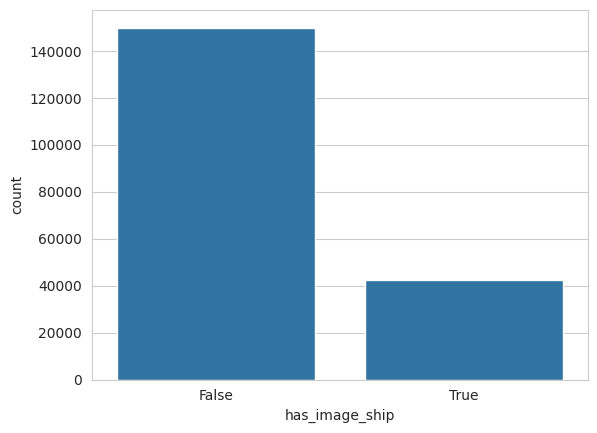

In [12]:
sns.countplot(data = has_image_ship, x = 'has_image_ship')

Images containing no ship is prevailing in dataset. Further we will examine can we downsample the dominating class(images with no ship in themselves).

In [14]:
ships_per_image = data.groupby(['ImageId'])['EncodedPixels'].agg(lambda x: sum(pd.notna(x)))\
                                                            .reset_index(name='ships_per_image')
data['ships_per_image'] = data.groupby(['ImageId'])['EncodedPixels'].transform(lambda x:  sum(pd.notna(x)))

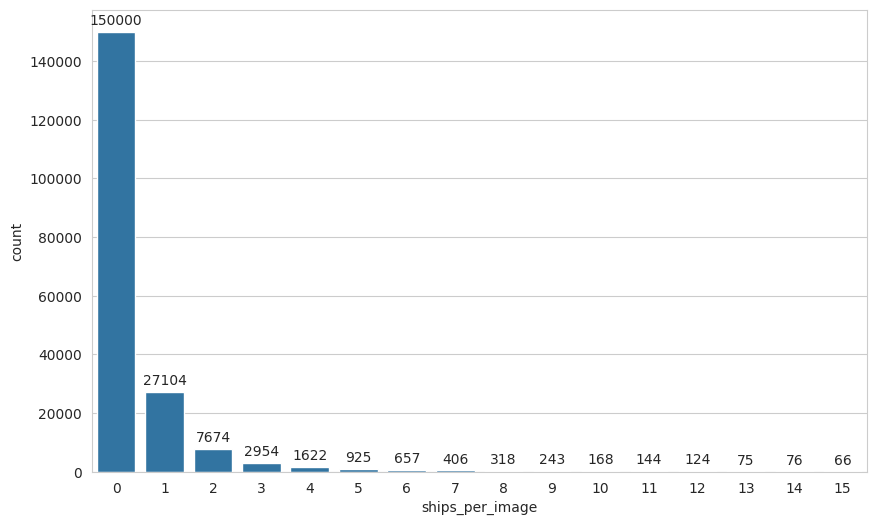

In [15]:
fig, ax = plt.subplots(figsize = (10, 6))
ax = sns.countplot(data = ships_per_image, x = 'ships_per_image')

for p in ax.patches:
  height = p.get_height()
  ax.annotate(
      f"{int(height)}",
      (p.get_x() + p.get_width() / 2.0, height),
      ha="center",
      va="bottom",
      xytext=(0, 3),  # 3 points vertical offset
      textcoords="offset points",
  )
plt.show()

In [16]:
data['RLE'] = data['EncodedPixels'].fillna('')
data['RLE']

0                                                          
1                                                          
2         264661 17 265429 33 266197 33 266965 33 267733...
3         360486 1 361252 4 362019 5 362785 8 363552 10 ...
4         51834 9 52602 9 53370 9 54138 9 54906 9 55674 ...
                                ...                        
231718                                                     
231719                                                     
231720                                                     
231721                                                     
231722                                                     
Name: RLE, Length: 231723, dtype: object

In [17]:
data.groupby('ImageId')['RLE'].agg(lambda x: " ".join(x))

ImageId
00003e153.jpg                                                     
0001124c7.jpg                                                     
000155de5.jpg    264661 17 265429 33 266197 33 266965 33 267733...
000194a2d.jpg    360486 1 361252 4 362019 5 362785 8 363552 10 ...
0001b1832.jpg                                                     
                                       ...                        
fffedbb6b.jpg                                                     
ffff2aa57.jpg                                                     
ffff6e525.jpg                                                     
ffffc50b4.jpg                                                     
ffffe97f3.jpg                                                     
Name: RLE, Length: 192556, dtype: object

In [43]:

def get_image_shape(file_path):

    try:
        with Image.open(file_path) as img:
            return img.size 
    except Exception:
        return None

image_dir = Path('/kaggle/input/competitions/airbus-ship-detection/train_v2/')
unique_shapes = set()

with ProcessPoolExecutor() as executor:
    results = executor.map(get_image_shape, 
                           list(image_dir.glob("*")), 
                           chunksize=500)
    
    for shape in results:
        if shape is not None:
            unique_shapes.add(shape)
unique_shapes

{(768, 768)}

Unique shape among all images is 768x768, so we cannot concern about arbitary size of input in model

In [19]:
def RLE_proportion(rle_arr: str, 
                shape: (int, int) = (768, 768)):
    total_area = shape[0]*shape[1]

    
    rle = list(map(int, rle_arr.split()))
    area_masking = sum(rle[1::2])

    return 100*np.float16(area_masking/total_area)

rles  = data[data['has_image_ship'].values].groupby('ImageId')['RLE']\
                                        .agg(lambda x: " ".join(x)).values
prop_of_label = []

with ProcessPoolExecutor() as executor:
    results = executor.map(RLE_proportion, 
                           rles, 
                           chunksize=500)
    
    prop_of_label += results



<Axes: ylabel='Count'>

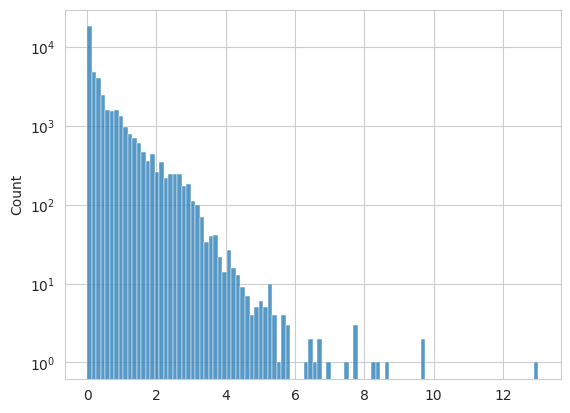

In [20]:
sns.histplot(x = prop_of_label, log = True, bins = 100)

In [21]:
print(f"Maximal percentage of labeled area among images -- {max(prop_of_label)}")

Maximal percentage of labeled area among images -- 13.015625


Maximal percentage of cover among all images is slighlty more than 13 percent. It means that background class is dominating in all images. As the result we can downsample images with no ships it it. 